# Análise para decisão de features

Este notebook responde quatro perguntas: o lote E-01 melhora de forma estável? Em quais canais ele piora? Em quais grupos de vídeos o erro é maior? Quais variáveis têm sinal para um próximo teste menor?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "scripts").is_dir() and (p / "src").is_dir())
EXPERIMENTS = ROOT / 'artifacts' / 'feature_experiments'
CONSUMPTION = pd.read_csv(ROOT / 'data' / 'gold' / 'pilot_consumption_table.csv', parse_dates=['published_at'])
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Escolha de features: rolling-origin, não teste final

O teste final pode ser visto como referência, mas a decisão de manter ou remover features é feita pelo rolling-origin. Menor MAE é melhor.

feature_set,E-00: baseline,E-01: texto/metadados,delta_E01_menos_E00
model,,,
B0,0.7734,0.7734,0.0000
M1,0.7798,0.7861,0.0063
M2,0.7615,0.7972,0.0357
M3,0.7620,0.7894,0.0275


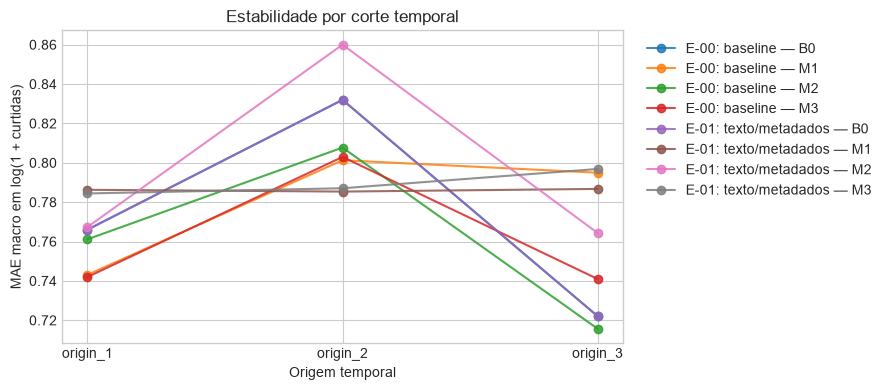

In [2]:
e00_rolling = pd.read_csv(EXPERIMENTS / 'e00' / 'rolling_origin_by_cut.csv')
e01_rolling = pd.read_csv(EXPERIMENTS / 'e01' / 'rolling_origin_by_cut.csv')
rolling = pd.concat([e00_rolling.assign(feature_set='E-00: baseline'), e01_rolling.assign(feature_set='E-01: texto/metadados')])
summary = (rolling.groupby(['feature_set', 'model'], as_index=False)['macro_mae_log_likes'].mean()
           .pivot(index='model', columns='feature_set', values='macro_mae_log_likes'))
summary['delta_E01_menos_E00'] = summary['E-01: texto/metadados'] - summary['E-00: baseline']
display(summary.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for feature_set, group in rolling.groupby('feature_set'):
    pivot = group.pivot(index='origin', columns='model', values='macro_mae_log_likes')
    for model in pivot.columns:
        ax.plot(pivot.index, pivot[model], marker='o', alpha=.85, label=f'{feature_set} — {model}')
ax.set(title='Estabilidade por corte temporal', xlabel='Origem temporal', ylabel='MAE macro em log(1 + curtidas)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

**Decisão:** se E-01 piorar a maior parte dos cortes ou aumentar o MAE médio, o lote não é retido, mesmo que melhore um único teste final.

## 2. Onde o lote ajuda ou prejudica?

Comparamos o M1 de E-00 e E-01 por canal. Valores positivos significam que E-01 aumentou o erro.

,channel_name,channel_type,e00,e01,delta
6,Honda Automoveis,brand,1.0285,0.9693,-0.0592
0,Acelerados,creator,0.8051,0.7573,-0.0478
4,EstiloRenner,brand,0.9437,0.9028,-0.0409
1,C&A Brasil,brand,0.9724,0.9458,-0.0265
11,Volkswagen do Brasil,brand,0.7283,0.7076,-0.0207
2,Carros com Camanzi,creator,0.5323,0.5511,0.0188
10,Steal The Look,creator,0.7059,0.7284,0.0225
8,Mandy Candy,creator,0.6378,0.6660,0.0282
9,NiinaSecrets,creator,0.9566,0.9939,0.0373
7,Hyundai Motor Brasil,brand,0.6435,0.6891,0.0457


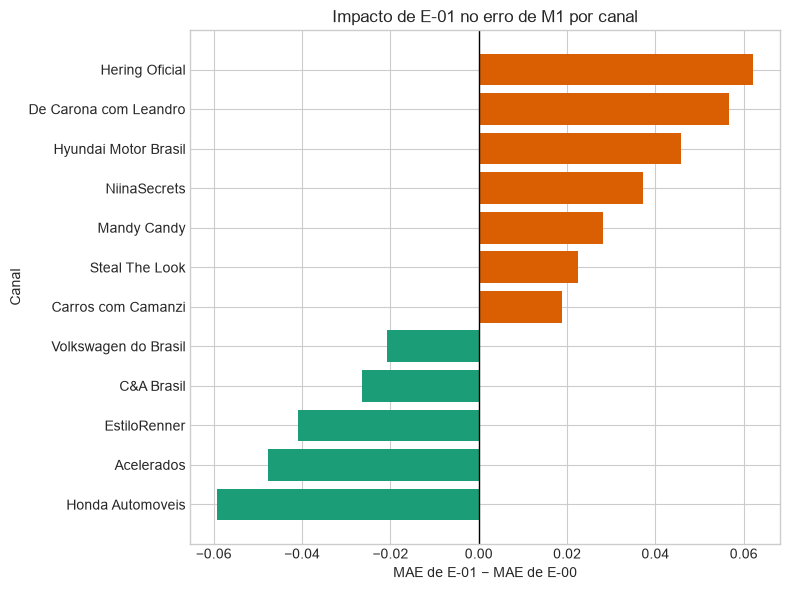

In [3]:
def channel_mae(experiment):
    data = pd.read_csv(EXPERIMENTS / experiment / 'rolling_origin_per_channel_metrics.csv')
    return (data.query("model == 'M1'")
            .groupby(['channel_name', 'channel_type'], as_index=False)['mae_log_likes'].mean()
            .rename(columns={'mae_log_likes': experiment}))

channel_delta = channel_mae('e00').merge(channel_mae('e01'), on=['channel_name', 'channel_type'])
channel_delta['delta'] = channel_delta['e01'] - channel_delta['e00']
display(channel_delta.sort_values('delta').round(4))

plot_data = channel_delta.sort_values('delta')
fig, ax = plt.subplots(figsize=(8, 6))
colors = np.where(plot_data['delta'] > 0, '#d95f02', '#1b9e77')
ax.barh(plot_data['channel_name'], plot_data['delta'], color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Impacto de E-01 no erro de M1 por canal', xlabel='MAE de E-01 − MAE de E-00', ylabel='Canal')
plt.tight_layout()

## 3. Erro condicionado às variáveis novas

Esses gráficos não provam causalidade. Eles mostram em quais formatos de vídeo o M1 de E-01 erra mais e se há amostra suficiente para uma hipótese posterior.

,has_cta,mae,bias,n,variavel
0,0,0.8010,-0.0159,680,CTA no texto
1,1,0.6648,0.2280,54,CTA no texto


,duration_bucket,mae,bias,n,variavel
0,01_15,0.6752,0.1278,130,Faixa de duração
1,16_30,0.7749,0.1315,164,Faixa de duração
2,31_60,0.8798,0.0021,166,Faixa de duração
3,61_180,0.8017,-0.1351,274,Faixa de duração


,overlap_group,mae,bias,n,variavel
0,0,0.7976,-0.0170,680,Sobreposição título/tags
1,0–25%,0.6951,0.2204,53,Sobreposição título/tags
2,>25%,1.3697,1.3697,1,Sobreposição título/tags


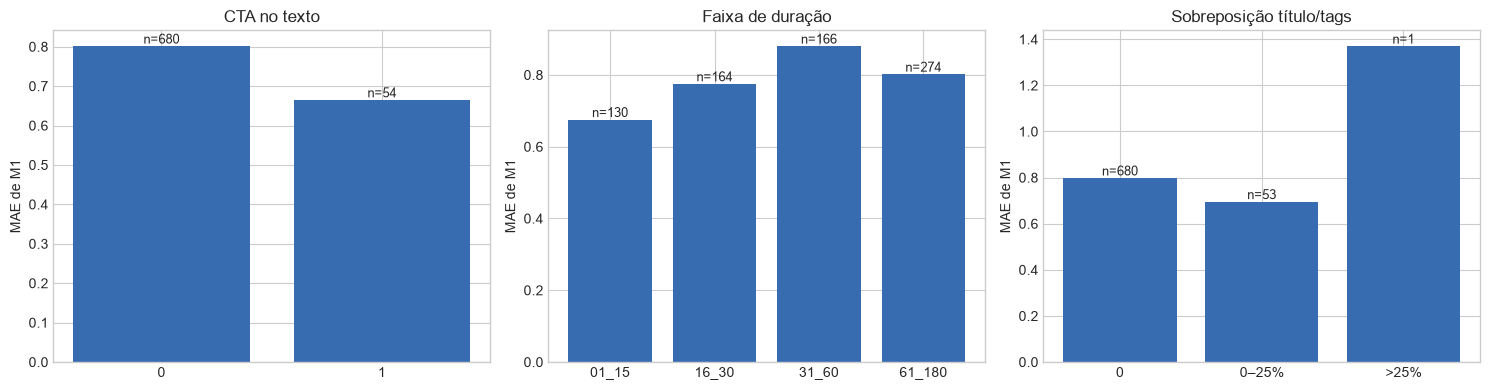

In [4]:
predictions = pd.read_csv(EXPERIMENTS / 'e01' / 'rolling_origin_predictions.csv')
m1 = predictions.query("model == 'M1'").merge(
    CONSUMPTION[['video_id', 'has_cta', 'duration_bucket', 'title_tag_overlap', 'channel_type']],
    on=['video_id', 'channel_type'], how='left'
)
m1['absolute_error'] = (m1['prediction_log_likes'] - m1['target_log_likes']).abs()
m1['residual'] = m1['prediction_log_likes'] - m1['target_log_likes']
m1['overlap_group'] = pd.cut(m1['title_tag_overlap'], [-.01, 0, .25, 1], labels=['0', '0–25%', '>25%'])

groups = [
    ('has_cta', 'CTA no texto'),
    ('duration_bucket', 'Faixa de duração'),
    ('overlap_group', 'Sobreposição título/tags'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (column, label) in zip(axes, groups):
    grouped = m1.groupby(column, observed=False).agg(mae=('absolute_error', 'mean'), bias=('residual', 'mean'), n=('video_id', 'size')).reset_index()
    display(grouped.assign(variavel=label).round(4))
    ax.bar(grouped[column].astype(str), grouped['mae'], color='#386cb0')
    for i, row in grouped.reset_index(drop=True).iterrows():
        ax.text(i, row['mae'], f"n={int(row['n'])}", ha='center', va='bottom', fontsize=9)
    ax.set(title=label, xlabel='', ylabel='MAE de M1')
plt.tight_layout()

## 4. O modelo erra mais em vídeos fracos ou fortes?

Dividimos o resultado observado em cinco faixas. Isso mostra heterocedasticidade: se o erro crescer muito nas faixas altas, o modelo está comprimindo possíveis sucessos excepcionais.

,resultado_faixa,mae,bias,videos
0,"(0.692, 2.485]",0.8305,0.7701,150
1,"(2.485, 3.258]",0.5178,0.1992,147
2,"(3.258, 4.301]",0.6203,-0.0357,143
3,"(4.301, 6.287]",0.8320,-0.1479,147
4,"(6.287, 10.285]",1.1491,-0.7923,147


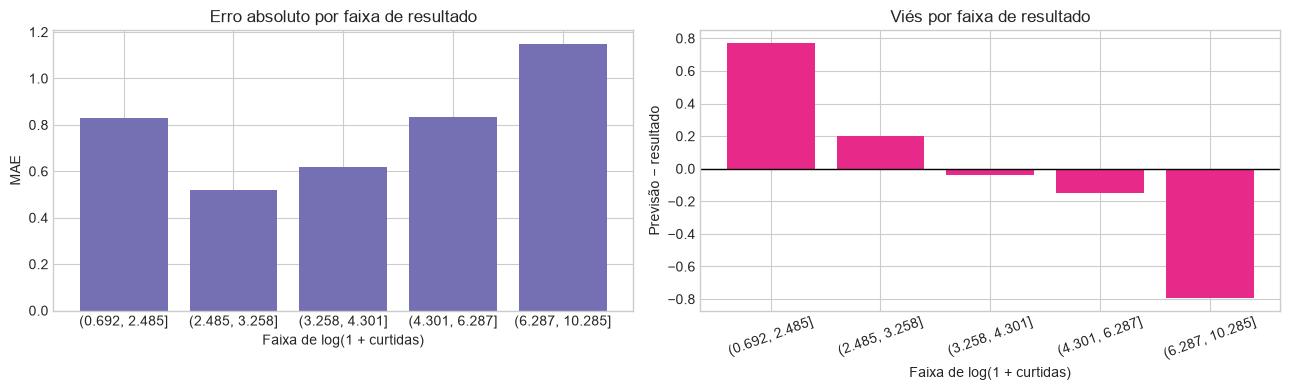

In [5]:
m1['resultado_faixa'] = pd.qcut(m1['target_log_likes'], q=5, duplicates='drop')
by_outcome = m1.groupby('resultado_faixa', observed=False).agg(
    mae=('absolute_error', 'mean'), bias=('residual', 'mean'), videos=('video_id', 'size')
).reset_index()
display(by_outcome.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(by_outcome['resultado_faixa'].astype(str), by_outcome['mae'], color='#7570b3')
axes[0].set(title='Erro absoluto por faixa de resultado', xlabel='Faixa de log(1 + curtidas)', ylabel='MAE')
axes[1].bar(by_outcome['resultado_faixa'].astype(str), by_outcome['bias'], color='#e7298a')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(title='Viés por faixa de resultado', xlabel='Faixa de log(1 + curtidas)', ylabel='Previsão − resultado')
plt.xticks(rotation=20)
plt.tight_layout()

## 5. Priorização de ablação

A importância por permutação é usada para selecionar subgrupos pequenos, não para declarar causalidade. Uma variável é uma candidata a ablação quando tem importância positiva e é calculável antes da publicação.

,feature,mean_mae_increase,ci_95_low,ci_95_high
2,has_cta,0.0748,0.0528,0.0982
5,title_tag_overlap,0.0193,0.0090,0.0275
6,duration_bucket,0.0192,0.0088,0.0311
10,publish_hour_cos,0.0079,0.0004,0.0150
12,has_question,0.0077,-0.0042,0.0179
14,title_word_count,0.0044,-0.0069,0.0130
15,hashtag_count,0.0043,0.0003,0.0083
16,uppercase_ratio,0.0027,0.0009,0.0043
17,is_weekend,0.0019,-0.0013,0.0055
18,digit_count,0.0014,-0.0054,0.0074


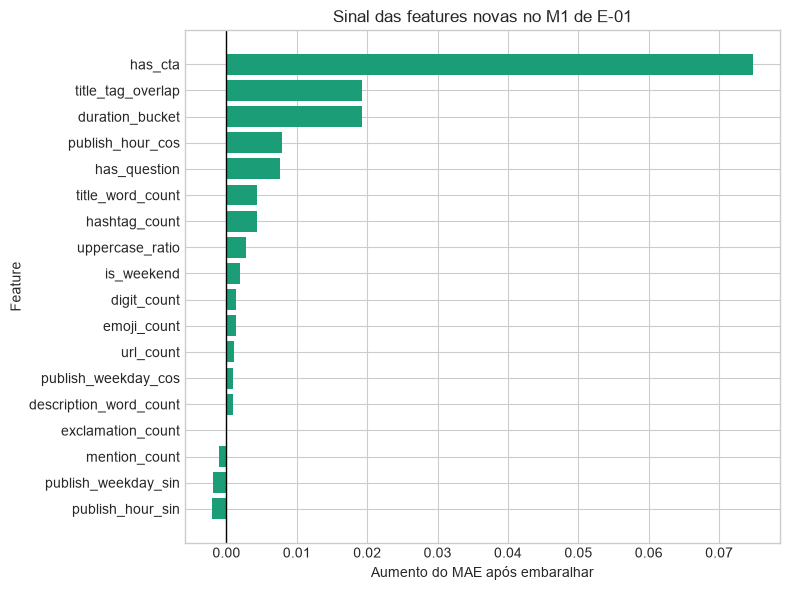

In [6]:
importance = pd.read_csv(EXPERIMENTS / 'e01' / 'permutation_importance_m1.csv')
new_features = {'has_cta', 'title_tag_overlap', 'duration_bucket', 'title_word_count', 'description_word_count', 'has_question', 'exclamation_count', 'emoji_count', 'hashtag_count', 'mention_count', 'url_count', 'digit_count', 'uppercase_ratio', 'publish_hour_sin', 'publish_hour_cos', 'publish_weekday_sin', 'publish_weekday_cos', 'is_weekend'}
candidates = importance[importance['feature'].isin(new_features)].copy()
display(candidates[['feature', 'mean_mae_increase', 'ci_95_low', 'ci_95_high']].round(4))

plot_data = candidates.sort_values('mean_mae_increase')
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_data['feature'], plot_data['mean_mae_increase'], color='#1b9e77')
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Sinal das features novas no M1 de E-01', xlabel='Aumento do MAE após embaralhar', ylabel='Feature')
plt.tight_layout()

## Decisão atual

E-01 não é retido como lote. O próximo experimento deve ser uma ablação pequena com `has_cta`, `title_tag_overlap` e `duration_bucket`, comparada contra E-00 no mesmo rolling-origin.